In [1]:
# Run in a fresh runtime, and use %pip (targets the notebook kernel)
%pip uninstall -y torch torchvision torchaudio xformers pillow
%pip cache purge -q

# Install the 2.9 combo from the SAME cu126 index
%pip install --no-cache-dir \
  torch==2.9.0+cu126 torchvision==0.24.0+cu126 pillow \
  --index-url https://download.pytorch.org/whl/cu126

# Now xformers that expects torch==2.9
%pip install --no-cache-dir -U xformers --index-url https://download.pytorch.org/whl/cu126


Found existing installation: torch 2.9.1+cu126
Uninstalling torch-2.9.1+cu126:
  Successfully uninstalled torch-2.9.1+cu126
Found existing installation: torchvision 0.24.0+cu126
Uninstalling torchvision-0.24.0+cu126:
  Successfully uninstalled torchvision-0.24.0+cu126
Found existing installation: xformers 0.0.33.post2
Uninstalling xformers-0.0.33.post2:
  Successfully uninstalled xformers-0.0.33.post2
Found existing installation: pillow 12.0.0
Uninstalling pillow-12.0.0:
  Successfully uninstalled pillow-12.0.0
Looking in indexes: https://download.pytorch.org/whl/cu126
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 MB 342.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 365.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.5/170.5 MB 359.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 183.5 MB/s eta 0:00:00
  Attempting uninstall: triton
    Found existing installation: triton 3.5.1
    Uninstalling triton-3.5.1

Looking in indexes: https://download.pytorch.org/whl/cu126
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 365.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 MB 323.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.5/170.5 MB 336.3 MB/s eta 0:00:00
  Attempting uninstall: triton
    Found existing installation: triton 3.5.0
    Uninstalling triton-3.5.0:
      Successfully uninstalled triton-3.5.0
  Attempting uninstall: torch
    Found existing installation: torch 2.9.0+cu126
    Uninstalling torch-2.9.0+cu126:
      Successfully uninstalled torch-2.9.0+cu126
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.24.0+cu126 requires torch==2.9.0, but you have torch 2.9.1+cu126 which is incompatible.


In [2]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

import os
os.chdir('/content/drive/MyDrive/ve/variance_analysis')

!pip install -e /content/drive/MyDrive/ve/variance_analysis

!pip -q install fonttools

!ttx -l fonts/Helvetica.ttc

!sudo mkdir -p /usr/share/fonts/truetype/helvetica
!ttx -y 0 -o /usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf fonts/Helvetica.ttc
!ttx -y 1 -o /usr/share/fonts/truetype/helvetica/Helvetica-Oblique.ttf fonts/Helvetica.ttc
!ttx -y 2 -o /usr/share/fonts/truetype/helvetica/Helvetica-Bold.ttf fonts/Helvetica.ttc
!ttx -y 3 -o /usr/share/fonts/truetype/helvetica/Helvetica-BoldOblique.ttf fonts/Helvetica.ttc

!fc-cache -fv


Mounted at /content/drive/
Obtaining file:///content/drive/MyDrive/ve/variance_analysis
  Preparing metadata (setup.py) ... done
  Attempting uninstall: variance_analysis
    Found existing installation: variance_analysis 0.1.0
    Uninstalling variance_analysis-0.1.0:
      Successfully uninstalled variance_analysis-0.1.0
  Running setup.py develop for variance_analysis
ERROR: specify a font number between 0 and 5 (inclusive)
Dumping "fonts/Helvetica.ttc" to "/usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf"...
Dumping 'GlyphOrder' table...
Dumping 'head' table...
Dumping 'hhea' table...
Dumping 'maxp' table...
Dumping 'OS/2' table...
Dumping 'hmtx' table...
Dumping 'hdmx' table...
Dumping 'cmap' table...
Dumping 'fpgm' table...
Dumping 'prep' table...
Dumping 'cvt ' table...
Dumping 'loca' table...
Dumping 'glyf' table...
Dumping 'kern' table...
Dumping 'name' table...
Dumping 'post' table...
Dumping 'Zapf' table...
Dumping 'feat' table...
Dumping 'meta' table...
Dumping 'mo

# Visualize Model Neurons

This notebook classifies neurons in models from Gornet and Thomson 2024 and Luo et al. 2024 such as the predictive coder and pretrained or randomized ResNet-18, ViT, etc.

The second section runs the variance explained analysis on each of the neurons and returns scatter plots.

In [3]:
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.font_manager as fm
import shutil

current_file_path = Path().resolve()
current_file_path

!mkdir -p ~/.fonts
!cp fonts/Helvetica.ttc ~/.fonts/

cache_dir = os.path.join(os.path.expanduser("~"), ".cache", "matplotlib")
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

fm._load_fontmanager(try_read_cache=False)
plt.rcParams['font.family'] = 'Helvetica'

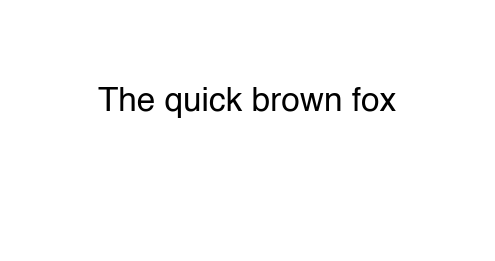

In [4]:
fig, ax = plt.subplots(figsize=(4, 2), dpi=150)
ax.text(0.5, 0.62, 'The quick brown fox', ha='center', va='center', fontsize=16)
ax.axis('off')
plt.show()


## Collect model activations

All models are shown observations from the same environment. The predictive coder is trained on views from smooth agent trajectories in this environment, and the rest of the models are either pretrained on ImageNet or randomized.

(4913, 64, 64, 3)


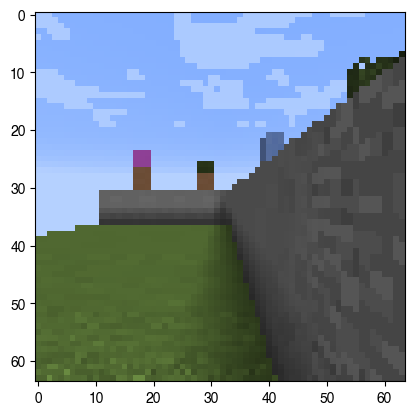

[120.5 197.5   0. ]


In [7]:
import numpy as np

model_name = 'resnet50' # predictive_coder | resnet50 | vit_b16 | resnet50_untrained | vgg16

# load in image observations and locations from the environment
obs_path = current_file_path / 'data/minecraft/small_world_r17_obs.npz'
coords_path = current_file_path / 'data/minecraft/small_world_r17_pos.npy'

obs = np.load(obs_path)['images']
coords = np.load(coords_path)

print(obs.shape)

# define unchanging args for the environment, previously was in config that I don't feel like messing with
N_ROTATIONS = 17
ENV_X_MIN = 120
ENV_X_MAX = 136
ENV_Y_MIN = 197
ENV_Y_MAX = 213

plt.imshow(obs[0])
plt.show()
print(coords[0])

# Variance Explained Analysis

Now let's see how much variance can be attributed to each of the possible stimulus dimensions for each neuron.

In [ ]:
# predictive code latents are pre-prediction/post-encoding ('pre_pred'), or post-prediction/pre-decoding residual stream ('post_pred')
# resnet can take layer1, layer3, layer4, or avgpool
# vit can take layer_{3, 6, 9, 12}
# vgg16 can take features.9, features.16, features.30, or classifier.3
# these are arbitrarily selected in Luo et al.

from src.ann.get_activations import load_model, get_activations

layer_name = 'layer3'

config = {
    'model_name': model_name,
    'output_layer': layer_name,
    'env_bounds': [ENV_X_MIN, ENV_X_MAX, ENV_Y_MIN, ENV_Y_MAX],
    'n_rotations': N_ROTATIONS
}

model, preprocess = load_model(model_name, base_path=current_file_path, output_layer=layer_name)


In [ ]:
import numpy as np

device = 'cuda'

# we add noise to inputs to simulate noise from a biological neuron
n_visits = 10
noise_frac = .26       # noise = noise_frac * (per-image, per-channel std)
seed = 3913
eps = 1e-8

n_locs, h, w, c = obs.shape
rng = np.random.default_rng(seed)

if np.issubdtype(obs.dtype, np.integer):
    obs_f = obs.astype(np.float32) / 255.0
else:
    obs_f = obs.astype(np.float32)

per_img_ch_std = obs_f.std(axis=(1, 2), keepdims=True) + eps   # (n_locs, 1, 1, c)

noise = rng.normal(loc=0.0, scale=1.0, size=(n_locs, n_visits, h, w, c)).astype(np.float32)

noise *= (noise_frac * per_img_ch_std[:, np.newaxis, ...]) # broadcast over visits

noisy_obs = obs_f[:, np.newaxis, ...] + noise # (n_locs, n_visits, h, w, c)
noisy_obs = np.clip(noisy_obs, 0.0, 1.0)

noisy_obs = noisy_obs.reshape(n_locs * n_visits, h, w, c)

noisy_acts_path = get_activations(
    model,
    preprocess,
    noisy_obs,
    model_name=model_name,
    layer_name=layer_name,
    device=device,
    batch_size=17,
    dest_dir=current_file_path / f'data/ann_activations/{model_name}_{layer_name}'
)


KeyboardInterrupt: 

In [ ]:
from pathlib import Path
from src.ann.classify_neurons import score_neurons, classify_neurons
import glob

acts_paths = [current_file_path / f'data/ann_activations/{model_name}_{layer_name}/acts.npz']
#acts_paths = glob.glob(str(current_file_path / f'data/ann_activations/{model_name}_{layer_name}/acts_*.npz'))
n_visits = 10

neuron_scores_fpath, sampled_path = score_neurons(
    acts_paths,
    config,
    base_dir=current_file_path,
    sample_partial=False,
    pixel_min_threshold=1,
    use_old_place_method=False,
    n_visits=n_visits
)

neuron_score_charts = np.load(neuron_scores_fpath, allow_pickle=True)
classifications = classify_neurons(neuron_score_charts)

classifications.keys()

Charting neurons:   0%|          | 0/8000 [00:00<?, ?neuron/s]

/content/drive/MyDrive/ve/variance_analysis/src/ann/score_utils.py:44: RuntimeWarning: invalid value encountered in scalar divide
  wall_scores.append((bi - c) / (bi + c))


[Saved] /content/drive/MyDrive/ve/variance_analysis/data/ann_activations/resnet50_layer3/neuron_chart.npy


dict_keys(['dead_neurons_indices', 'place_border_direction_cells_indices', 'place_and_border_not_direction_cells_indices', 'place_and_direction_not_border_cells_indices', 'border_and_direction_not_place_cells_indices', 'exclusive_place_cells_indices', 'exclusive_border_cells_indices', 'exclusive_direction_cells_indices', 'active_no_type_indices'])

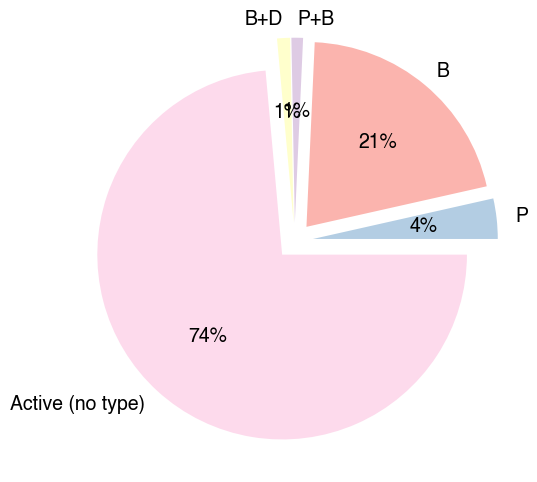

In [ ]:
from src.ann.fig import plot_cell_type_pie

fig = plot_cell_type_pie(classifications)
fig.savefig(current_file_path / f'figs/{model_name}_{layer_name}_breakdown.pdf')
plt.show()

In [9]:
from numba import njit, prange
import numpy as np

@njit(parallel=True, fastmath=True)
def get_splits_numba(visits, min_visits=2, seed=0):
    np.random.seed(seed)

    s1_bins, s2_bins, n_max_visits, n_neurons = visits.shape
    total_mean = np.full((s1_bins, s2_bins, n_neurons), np.nan)
    train_mean = total_mean.copy()
    test_mean  = total_mean.copy()
    train_occ  = np.zeros((s1_bins, s2_bins))
    test_occ   = np.zeros((s1_bins, s2_bins))

    for s1 in prange(s1_bins):
        for s2 in range(s2_bins):
            for n in range(n_neurons):
                valid = np.where(~np.isnan(visits[s1, s2, :, n]))[0]
                cnt   = valid.size
                if cnt < min_visits:
                    continue

                perm   = np.random.permutation(cnt)
                idx    = valid[perm]

                half   = cnt // 2
                tr_idx = idx[:half]
                te_idx = idx[half:]

                train_vals = visits[s1, s2, tr_idx, n]
                test_vals  = visits[s1, s2, te_idx, n]

                train_mean[s1, s2, n] = train_vals.mean()
                test_mean [s1, s2, n] = test_vals.mean()
                total_mean[s1, s2, n] = visits[s1, s2, idx, n].mean()

            train_occ[s1, s2] = tr_idx.size
            test_occ [s1, s2] = te_idx.size

    return total_mean, train_mean, test_mean, train_occ, test_occ

In [ ]:
from tqdm import tqdm
from src.explained_variance import *
from scipy.ndimage import zoom

raw_visits = np.load(acts_paths[0])['activations']
raw_visits = raw_visits.reshape(17*17*17, n_visits, -1)

raw_visits = raw_visits.reshape(17, 17, 17, n_visits, -1)
raw_visits = raw_visits.reshape(17 * 17, 17, n_visits, -1)

_, _, _, n_neurons = raw_visits.shape

place_cells = np.asarray(classifications['exclusive_place_cells_indices'])
is_place = np.isin(np.arange(n_neurons), place_cells)

sigma = (1,1)

zoom_factor = (1, N_ROTATIONS) # just scale so the dimensions are the same size

total_mean, fold0, fold1, fold0_occ, fold1_occ = get_splits_numba(raw_visits, seed=413)
occ = fold0_occ * 2

n_using = 7000
n_using = min(n_using, n_neurons)
neurons = list(range(n_neurons))
np.random.shuffle(neurons)

s1_var = np.zeros((n_using))
s2_var = np.zeros((n_using))

is_place_trunc = np.zeros((n_using), dtype=bool)

for i, n in tqdm(enumerate(neurons[:n_using])):
    f0 = nan_aware_gaussian_filter(fold0[:, :, n], sigma=sigma)
    f1 = nan_aware_gaussian_filter(fold1[:, :, n], sigma=sigma)
    f0 = masked_zoom(f0, zoom_factor=zoom_factor)
    f1 = masked_zoom(f1, zoom_factor=zoom_factor)
    occ_z = masked_zoom(occ, zoom_factor=zoom_factor)

    s1_var[i] = quantify_variance(f0, f1, occ_z, axis=0)[0]
    s2_var[i] = quantify_variance(f0, f1, occ_z, axis=1)[0]
    is_place_trunc[i] = is_place[n]


7000it [01:49, 63.87it/s]


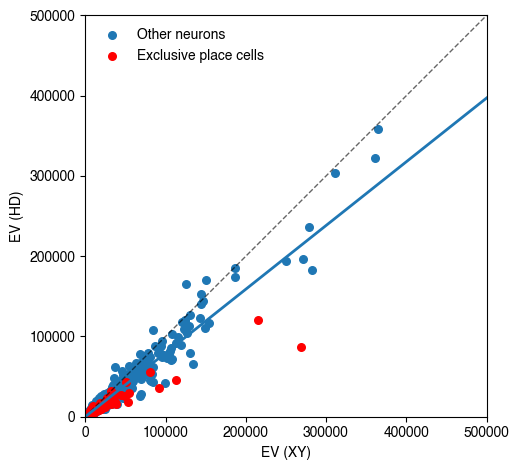

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Original scatters
plt.scatter(
    s1_var[~is_place_trunc],
    s2_var[~is_place_trunc],
    s=30,
    label="Other neurons"
)

plt.scatter(
    s1_var[is_place_trunc],
    s2_var[is_place_trunc],
    color="red",
    s=30,
    label="Exclusive place cells"
)

vals = np.concatenate([np.asarray(s1_var).ravel(), np.asarray(s2_var).ravel()])
vmin, vmax = np.nanmin(vals), np.nanmax(vals)
plt.plot([vmin, vmax], [vmin, vmax], "--", lw=1, color="k", alpha=0.6)

x_all = np.asarray(s1_var, dtype=float).ravel()
y_all = np.asarray(s2_var, dtype=float).ravel()

valid = np.isfinite(x_all) & np.isfinite(y_all)
xv = x_all[valid]
yv = y_all[valid]

# fitting line of best fit
def iqr_mask(a, whisker=1.5):
    if a.size == 0:
        return np.zeros_like(a, dtype=bool)
    q1 = np.percentile(a, 25)
    q3 = np.percentile(a, 70)
    iqr = q3 - q1
    lo = q1 - whisker * iqr
    hi = q3 + whisker * iqr
    return (a >= lo) & (a <= hi)

mx = iqr_mask(xv)
my = iqr_mask(yv)
inliers = mx & my

x_in = xv[inliers]
y_in = yv[inliers]

if x_in.size >= 2:
    m, b = np.polyfit(x_in, y_in, 1)
    ax = plt.gca()
    x_fit = np.linspace(*ax.get_xlim(), 200)
    y_fit = m * x_fit + b
    plt.plot(x_fit, y_fit, lw=2)

plt.gca().set_aspect("equal", adjustable="box")

plt.xlim(0, 500000)
plt.ylim(0, 500000)

plt.xlabel("EV (XY)")
plt.ylabel("EV (HD)")
# plt.title(f"Per-neuron explained variance, {model_name}, layer: {layer_name}")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig(current_file_path / f'figs/{model_name}_{layer_name}_ev.pdf')
plt.show()


In [ ]:
import sys, subprocess, importlib.util
from importlib.metadata import version, PackageNotFoundError

# 1) Remove the wrong kaleido
subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "kaleido"])

# 2) Install the Plotly kaleido
subprocess.check_call([sys.executable, "-m", "pip", "install", "kaleido==0.2.1"])

# 3) Verify the right module layout
print("Kaleido version:", version("kaleido"))
print("kaleido.scopes.plotly importable?:",
      importlib.util.find_spec("kaleido.scopes.plotly") is not None)


Kaleido version: 0.2.1
kaleido.scopes.plotly importable?: True


In [ ]:
import numpy as np
from src.ann.fig import plot_neuron_2d_3d

# -------------------------------------------------
# Config: choose which neurons to look at
# -------------------------------------------------
ratio_mode = "xy"   # "xy" → XY-preferring neurons, "hd" → HD-preferring neurons
rank_idx = 3      # 0 = top neuron, 1 = second, etc.

# Normalize EVs across both signals
lo = np.nanmin([np.nanmin(s1_var), np.nanmin(s2_var)])
hi = np.nanmax([np.nanmax(s1_var), np.nanmax(s2_var)])

s1_norm = (s1_var - lo) / (hi - lo)   # normalized EV(XY)
s2_norm = (s2_var - lo) / (hi - lo)   # normalized EV(HD)

# Flatten in case they're not already 1D
ev_xy = np.asarray(s1_norm, dtype=float).ravel()
ev_hd = np.asarray(s2_norm, dtype=float).ravel()

# -------------------------------------------------
# EV ratios (exactly like your md/hd example)
# -------------------------------------------------
denom = ev_xy + ev_hd
denom[denom == 0] = np.finfo(float).eps  # avoid division by zero

xy_ratio = ev_xy / denom   # fraction of EV carried by XY
hd_ratio = ev_hd / denom   # fraction of EV carried by HD

# Sort indices by ratio (descending)
most_xy = np.argsort(xy_ratio)[::-1]
most_hd = np.argsort(hd_ratio)[::-1]

if ratio_mode == "xy":
    ranking = most_xy
    ratios = xy_ratio
elif ratio_mode == "hd":
    ranking = most_hd
    ratios = hd_ratio
else:
    raise ValueError("ratio_mode must be 'xy' or 'hd'")

# Pick neuron by rank
neuron_idx = int(ranking[rank_idx])
ev_for_this_neuron = float(ratios[neuron_idx])
print(f"Selected neuron {neuron_idx} (rank {rank_idx}) "
      f"with {ratio_mode.upper()} EV ratio = {ev_for_this_neuron:.3f}")

# -------------------------------------------------
# Prepare rate map tensor for plotting
# -------------------------------------------------
tm = total_mean.reshape(17, 17, 17, -1)
tm = np.moveaxis(tm, -1, 0)   # (neurons, x, y, hd) or similar

# Because it's a transformer unit, shift if there are negatives
m = np.nanmin(tm[neuron_idx])
if m < 0:
    tm[neuron_idx] -= m + 1e-8

tm[neuron_idx] = nan_aware_gaussian_filter(tm[neuron_idx], (1, 1, 1))

#low_p, high_p = 1, 99
#cmin = float(np.nanpercentile(tm[neuron_idx], low_p))
#cmax = float(np.nanpercentile(tm[neuron_idx], high_p))
#tm[neuron_idx] = np.clip(tm[neuron_idx], a_min=cmin, a_max=cmax)

# -------------------------------------------------
# Plot with your 2D/3D helper
# -------------------------------------------------
fig = plot_neuron_2d_3d(
    tm,
    neuron_idx=neuron_idx,
    axes_names=("X", "Y", "HD (°)"),
    n_slices=3,
    z_spacing=1.0,
    surf_opacity=1.0,
    grid_color="white",
    grid_width=1,
    z_label_degrees=True,
    # overall_title=f"{model_name} {ratio_mode.upper()}-preferring, rank {rank_idx}",
)

fig.update_layout(
    paper_bgcolor="white",
    plot_bgcolor="white",
    margin=dict(l=60, r=100, t=80, b=60),
)
fig.update_scenes(
    dict(
        bgcolor="white",
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False),
    ),
    row=1, col=1
)

fig.write_image(
    current_file_path / f'figs/{model_name}_{layer_name}_N{neuron_idx}_{ratio_mode}_rank{rank_idx}.pdf'
)
fig.show()


Selected neuron 5148 (rank 3) with XY EV ratio = 0.753


## Loop for scatter plots

In [11]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from src.ann.classify_neurons import score_neurons, classify_neurons
from src.explained_variance import nan_aware_gaussian_filter, masked_zoom, quantify_variance

# ---------------------------------------------------------------------
# Model / layer config and grid constants
# ---------------------------------------------------------------------
models_and_layers = {
    "resnet50": ["layer1", "layer3", "layer4", "avgpool"],
    "predictive_coder": ["pre_pred", "post_pred"],
}

N_POS_X = 17
N_POS_Y = 17
N_ROTATIONS = 17

max_ev_neurons = 3000        # compute EVs for at most this many neurons
max_scatter_points = 200     # show at most this many points in the scatter

rng_vis = np.random.default_rng(0)


def iqr_mask(a, whisker=1.5):
    """Return a boolean mask of inliers using an IQR rule."""
    q1 = np.percentile(a, 25)
    q3 = np.percentile(a, 75)
    iqr = q3 - q1
    lo = q1 - whisker * iqr
    hi = q3 + whisker * iqr
    return (a >= lo) & (a <= hi)


# ---------------------------------------------------------------------
# Main loop: model × layer → EV(XY) vs EV(HD) scatter + density
# ---------------------------------------------------------------------
for model_name, layer_names in models_and_layers.items():
    for layer_name in layer_names:
        print(f"\n=== {model_name} / {layer_name} ===")

        # ---------------------------------------------------------
        # Load activations for this model/layer
        # ---------------------------------------------------------
        acts_path = current_file_path / f"data/ann_activations/{model_name}_{layer_name}/acts.npz"
        if not acts_path.exists():
            print(f"  Skipping: activations not found at {acts_path}")
            continue

        acts = np.load(acts_path)["activations"]  # (n_locs * n_visits, n_neurons)
        n_total, n_neurons = acts.shape

        n_locs = N_POS_X * N_POS_Y * N_ROTATIONS
        if n_total % n_locs != 0:
            raise ValueError(
                f"Unexpected activations shape {acts.shape} for {model_name}/{layer_name}; "
                f"not divisible by {n_locs} (17*17*17)."
            )
        n_visits = n_total // n_locs
        print(f"  n_neurons={n_neurons}, n_visits={n_visits}")

        # match your original reshaping
        raw_visits = acts.reshape(n_locs, n_visits, -1)
        raw_visits = raw_visits.reshape(N_POS_X, N_POS_Y, N_ROTATIONS, n_visits, -1)
        raw_visits = raw_visits.reshape(N_POS_X * N_POS_Y, N_ROTATIONS, n_visits, -1)

        # ---------------------------------------------------------
        # Classify neurons: place vs other
        # ---------------------------------------------------------
        config = {
            "model_name": model_name,
            "output_layer": layer_name,
            "env_bounds": [ENV_X_MIN, ENV_X_MAX, ENV_Y_MIN, ENV_Y_MAX],
            "n_rotations": N_ROTATIONS,
        }

        acts_paths = [acts_path]
        neuron_scores_fpath, _ = score_neurons(
            acts_paths,
            config,
            base_dir=current_file_path,
            sample_partial=False,
            pixel_min_threshold=1,
            use_old_place_method=False,
            n_visits=n_visits,
        )

        neuron_score_charts = np.load(neuron_scores_fpath, allow_pickle=True)
        classifications = classify_neurons(neuron_score_charts)

        place_cells = np.asarray(classifications["exclusive_place_cells_indices"])
        is_place = np.isin(np.arange(n_neurons), place_cells)

        # ---------------------------------------------------------
        # Split visits with your existing Numba function
        # ---------------------------------------------------------
        sigma = (1, 1)
        zoom_factor = (1, N_ROTATIONS)  # scale HD so axes comparable

        total_mean, fold0, fold1, fold0_occ, fold1_occ = get_splits_numba(raw_visits, seed=413)
        occ = fold0_occ * 2  # approximate total occupancy

        # ---------------------------------------------------------
        # Compute EV(XY) vs EV(HD) for up to max_ev_neurons neurons
        # ---------------------------------------------------------
        n_using = min(max_ev_neurons, n_neurons)
        neuron_indices = np.arange(n_neurons)
        rng_vis.shuffle(neuron_indices)
        neuron_indices = neuron_indices[:n_using]

        s1_var = np.zeros(n_using)
        s2_var = np.zeros(n_using)
        is_place_trunc = np.zeros(n_using, dtype=bool)

        for i, n in tqdm(
            list(enumerate(neuron_indices)),
            total=n_using,
            desc=f"  EV per neuron ({model_name}, {layer_name})",
        ):
            f0 = nan_aware_gaussian_filter(fold0[:, :, n], sigma=sigma, circular_axes=(0, 1))
            f1 = nan_aware_gaussian_filter(fold1[:, :, n], sigma=sigma, circular_axes=(0, 1))

            f0 = masked_zoom(f0, zoom_factor=zoom_factor)
            f1 = masked_zoom(f1, zoom_factor=zoom_factor)
            occ_z = masked_zoom(occ, zoom_factor=zoom_factor)

            s1_var[i] = quantify_variance(f0, f1, occ_z, axis=0)[0]  # XY
            s2_var[i] = quantify_variance(f0, f1, occ_z, axis=1)[0]  # HD
            is_place_trunc[i] = is_place[n]

        # ---------------------------------------------------------
        # Outlier rejection + subsample for scatter
        # ---------------------------------------------------------
        x_all = s1_var.astype(float).ravel()
        y_all = s2_var.astype(float).ravel()
        valid = np.isfinite(x_all) & np.isfinite(y_all)
        xv = x_all[valid]
        yv = y_all[valid]
        is_place_valid = is_place_trunc[valid]

        if xv.size == 0:
            print("  No valid EV values; skipping plots.")
            continue

        # IQR-based inliers on both axes
        mx = iqr_mask(xv)
        my = iqr_mask(yv)
        inliers = mx & my
        if inliers.sum() == 0:
            inliers = valid  # fallback: use all valid points if IQR is degenerate

        xv_in = xv[inliers]
        yv_in = yv[inliers]
        place_in = is_place_valid[inliers]

        # choose up to max_scatter_points to plot
        idx_in = np.arange(xv_in.size)
        rng_vis.shuffle(idx_in)
        if xv_in.size > max_scatter_points:
            idx_in = idx_in[:max_scatter_points]

        xv_plot = xv_in#[idx_in]
        yv_plot = yv_in#[idx_in]
        place_plot = place_in#[idx_in]

        # ---------------------------------------------------------
        # Scatter plot (subset of 200 inlier points)
        # ---------------------------------------------------------
        fig, ax = plt.subplots(figsize=(4, 4), dpi=150)

        # other neurons
        ax.scatter(
            xv_plot[~place_plot][:200],
            yv_plot[~place_plot][:200],
            s=30,
            label="Other neurons",
        )
        # exclusive place cells
        ax.scatter(
            xv_plot[place_plot][:100],
            yv_plot[place_plot][:100],
            s=30,
            color="red",
            label="Exclusive place cells",
        )

        # diagonal reference line
        vals = np.concatenate([xv_in, yv_in])
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        ax.plot([vmin, vmax], [vmin, vmax], "--", lw=1, color="k", alpha=0.6)

        # robust linear fit on all inliers (not just the 200)
        if xv_in.size >= 2:
            m, b = np.polyfit(xv_in, yv_in, 1)
            x_fit = np.linspace(vmin, vmax, 200)
            y_fit = m * x_fit + b
            ax.plot(x_fit, y_fit, lw=2)

        ax.set_aspect("equal", adjustable="box")
        #ax.set_xlim(0, 500000)
        #ax.set_ylim(0, 500000)
        ax.set_xlabel("EV (XY)")
        ax.set_ylabel("EV (HD)")
        ax.set_title(f"{model_name}, layer: {layer_name}")
        ax.legend(frameon=False)
        fig.tight_layout()

        scatter_out_path = current_file_path / f"figs/{model_name}_{layer_name}_ev_scatter.pdf"
        scatter_out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(scatter_out_path)
        plt.close(fig)

        print(f"  Saved scatter to {scatter_out_path}")

        # ---------------------------------------------------------
        # Density plot (hexbin) using all inliers
        # ---------------------------------------------------------
        fig_d, ax_d = plt.subplots(figsize=(4, 4), dpi=150)

        hb = ax_d.hexbin(
            xv_in,
            yv_in,
            gridsize=50,
            bins="log",
        )

        # diagonal and same linear fit
        ax_d.plot([vmin, vmax], [vmin, vmax], "--", lw=1, color="k", alpha=0.6)
        if xv_in.size >= 2:
            x_fit = np.linspace(vmin, vmax, 200)
            y_fit = m * x_fit + b
            ax_d.plot(x_fit, y_fit, lw=2)

        ax_d.set_aspect("equal", adjustable="box")
        #ax_d.set_xlim(0, 500000)
        #ax_d.set_ylim(0, 500000)
        ax_d.set_xlabel("EV (XY)")
        ax_d.set_ylabel("EV (HD)")
        ax_d.set_title(f"{model_name}, layer: {layer_name} (density)")
        cb = fig_d.colorbar(hb, ax=ax_d)
        cb.set_label("log(count)")

        fig_d.tight_layout()

        density_out_path = current_file_path / f"figs/{model_name}_{layer_name}_ev_density.pdf"
        density_out_path.parent.mkdir(parents=True, exist_ok=True)
        fig_d.savefig(density_out_path)
        plt.close(fig_d)

        print(f"  Saved density plot to {density_out_path}")



=== resnet50 / layer1 ===
  n_neurons=8000, n_visits=10


Charting neurons:   0%|          | 0/8000 [00:00<?, ?neuron/s]

/content/drive/MyDrive/ve/variance_analysis/src/ann/score_utils.py:44: RuntimeWarning: invalid value encountered in scalar divide
  wall_scores.append((bi - c) / (bi + c))


[Saved] /content/drive/MyDrive/ve/variance_analysis/data/ann_activations/resnet50_layer1/neuron_chart.npy


  EV per neuron (resnet50, layer1): 100%|██████████| 3000/3000 [00:46<00:00, 64.19it/s]


...

Charting neurons:   0%|          | 0/8000 [00:00<?, ?neuron/s]

/content/drive/MyDrive/ve/variance_analysis/src/ann/score_utils.py:44: RuntimeWarning: invalid value encountered in scalar divide
  wall_scores.append((bi - c) / (bi + c))


[Saved] /content/drive/MyDrive/ve/variance_analysis/data/ann_activations/predictive_coder_post_pred/neuron_chart.npy


  EV per neuron (predictive_coder, post_pred): 100%|██████████| 3000/3000 [00:46<00:00, 64.27it/s]


  Saved scatter to /content/drive/MyDrive/ve/variance_analysis/figs/predictive_coder_post_pred_ev_scatter.pdf
  Saved density plot to /content/drive/MyDrive/ve/variance_analysis/figs/predictive_coder_post_pred_ev_density.pdf
